In [1]:
# ติดตั้งแพ็กเกจเมื่อรันใน repo — บน Kaggle มี pandas/matplotlib พร้อมอยู่แล้ว
from pathlib import Path

if Path("requirements-offline.txt").exists():
    get_ipython().run_line_magic(
        "pip", "install -r requirements-offline.txt --quiet")
else:
    print("ข้ามการติดตั้ง — ใช้แพ็กเกจที่มีใน environment (เช่น Kaggle)")

/Users/utarn/projects/datascience-metrology/.check-env/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


# Module M6 — พยากรณ์อย่างง่าย

|  |  |
|---|---|
| **เวลา** | Day 2, 12:30–13:45 (75 นาที) · Offline (CPU) |
| **ข้อมูล** | NOAA CO₂ · AirPassengers · นักท่องเที่ยวต่างชาติ · PM2.5 · ราคาข้าว |

**เมื่อจบโมดูลนี้ ผู้เรียนจะ...**

- มองไปข้างหน้าด้วยเครื่องมือสถิติ 3 ตัว: **trend line · moving average · วงรอบ**
- ตรวจความน่าเชื่อของการพยากรณ์ด้วยวิธี "ซ่อนท้าย–ทำนาย–เทียบจริง"
- จับ**กับดัก extrapolation** — เหตุผลอันดับหนึ่งที่คนพยากรณ์ผิด

**ข้อมูลที่ใช้ (citation):**

> Lan, X., Tans, P. & Thoning, K.W. (2026). *Trends in globally-averaged
> CO2* NOAA GML, Version 2026-09, doi:10.15138/9N0H-ZH07 (US Government
> product — ใช้ฟรีพร้อมใส่เครดิต)
>
> Box, G. E. P. & Jenkins, G. M. (1976). *Time Series Analysis* —
> AirPassengers (ผ่าน Rdatasets)
>
> สำนักงานปลัดกระทรวงการท่องเที่ยวและกีฬา (CC BY) · กรมควบคุมมลพิษ
> (Open Data Common) · สำนักงานเศรษฐกิจการเกษตร (Open Data Common)

## 1. พยากรณ์ = ต่อเส้นจากอดีต — ด้วยเครื่องมือง่าย ๆ สามตัว

เราจะไม่พึ่งเวทมนตร์ใด ๆ — ทั้งหมดคือคณิตมัธยมปลายที่คอมพิวเตอร์คำนวณให้:

| เครื่องมือ | ทำอะไร | เมื่อไหร่ใช้ |
|---|---|---|
| **trend line** | เส้นตรงที่พอดีข้อมูลมากที่สุด | แนวโน้มระยะยาว |
| **moving average** | เฉลี่ยข้างเคียง n จุด เลื่อนไปเรื่อย ๆ | กรองเสียงรบกวนให้เห็นทิศ |
| **วงรอบ** | ความซ้ำที่มาทุกช่วงเวลาเท่ากัน | ฤดูกาล/เทศกาล |

และกติกาประจำโมดูล: **ทุกการพยากรณ์ต้องผ่านการตรวจ** — เราจะซ่อนช่วงท้าย
ข้อมูลไว้ ให้เส้นทำนาย แล้วเทียบกับของจริง ก่อนเชื่อมันแนะนำอนาคต

In [2]:
import numpy as np  # noqa: E402
import pandas as pd
from pathlib import Path

import os


def data_root() -> Path:
    """หาโฟลเดอร์ datasets/ — ใช้ได้ทั้ง repo local, venv และ Kaggle.

    ลำดับการค้นหา:
    1. environment variable COURSE_DATA_ROOT (ชี้ตรงไปที่โฟลเดอร์ datasets)
    2. โฟลเดอร์ datasets/ ที่อยู่ระดับเดียวกับโน้ตบุ๊กหรือแม่ขึ้นไป
       (repo local)
    3. /kaggle/input — ทั้งกรณีอัปโหลด datasets/ ทั้งโฟลเดอร์
       หรืออัปโหลดแต่ละชุดแยกกัน (ชื่อโฟลเดอร์ต้องตรงกับใน datasets/)
    """
    env = os.environ.get("COURSE_DATA_ROOT")
    if env:
        return Path(env)
    for p in (Path.cwd(), *Path.cwd().parents):
        if (p / "datasets").is_dir():
            return p / "datasets"
    kaggle = Path("/kaggle/input")
    if kaggle.is_dir():
        hits = sorted(kaggle.glob("**/datasets"))
        if hits:
            return hits[0]
        return kaggle
    raise SystemExit(
        "ไม่พบโฟลเดอร์ datasets/ — ตั้ง COURSE_DATA_ROOT "
        "หรือวาง datasets/ ไว้ข้างโน้ตบุ๊ก")

DATA = data_root()

# CO2 โลก (ppm) รายเดือน 1979–2026 — ไฟล์มีหัวคำอธิบาย 38 บรรทัด (M3)
co2 = pd.read_csv(DATA / "noaa_co2" / "co2_mm_gl.csv", skiprows=38)
co2["date"] = pd.to_datetime(
    dict(year=co2["year"], month=co2["month"], day=1))
print(f"{len(co2)} เดือน จาก {co2['year'].min()}"
      f" ถึง {co2['year'].max()}")

570 เดือน จาก 1979 ถึง 2026


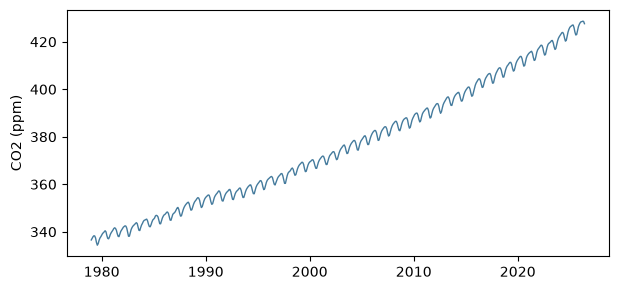

In [3]:
import matplotlib.pyplot as plt  # noqa: E402

plt.rcParams["font.family"] = [
    "DejaVu Sans", "Noto Sans Thai", "Leelawadee UI", "Tahoma",
]

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(co2["date"], co2["average"], color="#457b9d", lw=1)
ax.set_ylabel("CO2 (ppm)")
plt.show()

อ่านกราฟได้สองชั้น:

1. **แนวโน้ม** — ขึ้นสม่ำเสมอจาก ~337 ถึง ~428 ppm (1979–2026)
2. **วงรอบรายปี** — หยักขึ้นลงประจำทุกปี (ต้นไม้ซีกโลกเหนือดูด CO2 ฤดูใบไม้ผลิ
   ปล่อยคืนฤดูใบไม้ร่วง)

เครื่องมือแรก: **moving average** — เฉลี่ย 12 เดือนที่เลื่อนไปเรื่อย ๆ
เหลือแต่แนวโน้ม วงรอบถูกกรองออก:

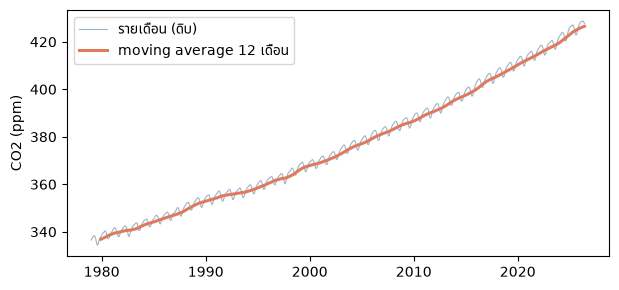

In [4]:
co2["ma12"] = co2["average"].rolling(12).mean()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(co2["date"], co2["average"], color="#9ab5c9", lw=0.8,
        label="รายเดือน (ดิบ)")
ax.plot(co2["date"], co2["ma12"], color="#e07a5f", lw=2.2,
        label="moving average 12 เดือน")
ax.legend()
ax.set_ylabel("CO2 (ppm)")
plt.show()

`.rolling(12).mean()` = ยืนอยู่จุดไหน มองย้อน 12 จุดแล้วเฉลี่ย
(เดือนแรก ๆ ยังรวมไม่ครบ 12 ค่า จึงว่างเปล่า — `NaN`)

เครื่องมือที่สอง: **trend line** — สมการเส้นตรง `y = a + b·x` ที่เรียนมัธยม
`np.polyfit` หา `a, b` ที่เส้นพอดีข้อมูลมากที่สุด แล้ว `np.polyval` คำนวณ
ค่า y ตามเส้นนั้น:

เส้นตรง: CO2 = -3,424 + 1.90 x ปี
แปลผล: CO2 เฉลี่ยขึ้นปีละ 1.90 ppm


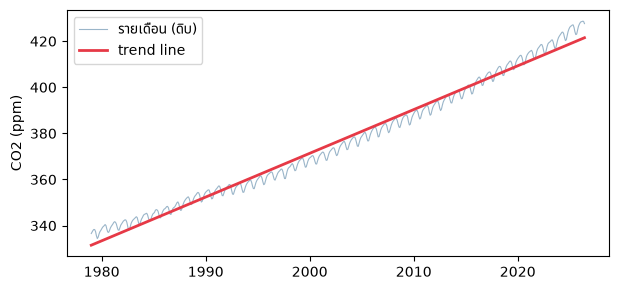

In [5]:
slope, intercept = np.polyfit(co2["decimal"], co2["average"], 1)
co2["trend"] = np.polyval([slope, intercept], co2["decimal"])

print(f"เส้นตรง: CO2 = {intercept:,.0f} + {slope:.2f} x ปี")
print(f"แปลผล: CO2 เฉลี่ยขึ้นปีละ {slope:.2f} ppm")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(co2["date"], co2["average"], color="#9ab5c9", lw=0.8,
        label="รายเดือน (ดิบ)")
ax.plot(co2["date"], co2["trend"], color="#e63946", lw=2,
        label="trend line")
ax.legend()
ax.set_ylabel("CO2 (ppm)")
plt.show()

ค่าความชัน (slope) คือสิ่งที่**พูดให้คนฟังได้**: "CO2 เฉลี่ยขึ้นปีละ
~2.4 ppm" — ตัวเลขหนึ่งตัวที่สรุป 570 เดือน

### ก่อนเชื่อเส้นนี้ — ตรวจตามกติกา

ซ่อน 20% ท้ายไว้ ให้เส้นเรียนจากช่วงต้น แล้วทำนายช่วงท้ายที่ซ่อนไว้
เทียบกับของจริง วัดด้วย **MAE** (Mean Absolute Error — พลาดเฉลี่ยกี่หน่วย):

In [6]:
cut = int(len(co2) * 0.8)          # 80% แรก = ฝึก, 20% ท้าย = สอบ
train = co2.iloc[:cut]
test = co2.iloc[cut:]

m, b = np.polyfit(train["decimal"], train["average"], 1)
pred = np.polyval([m, b], test["decimal"])
mae = (test["average"] - pred).abs().mean()
print(f"พยากรณ์ช่วงสอบ: พลาดเฉลี่ย {mae:.1f} ppm "
      f"(ของจริงอยู่ช่วง {test['average'].min():.0f}"
      f"–{test['average'].max():.0f})")

พยากรณ์ช่วงสอบ: พลาดเฉลี่ย 7.8 ppm (ของจริงอยู่ช่วง 403–429)


พลาดเฉลี่ย ~8 ppm บนช่วงข้อมูลกว้าง ~90 ppm — ราว 2% โดยรวมน่าเชื่อ
สำหรับการทำนายช่วงสั้น แต่สังเกตให้เห็น: ช่วงสอบยาวถึง 9 ปี และช่วงท้าย
เส้นตรงเริ่มตามไม่ทัน (CO2 เพิ่มเร่งขึ้น) — แม้กระทั่งข้อมูล "ขึ้นสม่ำเสมอ"
แบบนี้ การยืดเส้นไกลก็เริ่มพลาดเพิ่มขึ้นเรื่อย ๆ

ข้อจำกัดที่ต้องพูดเสมอ: ทำนายได้ดีแค่ไหนขึ้นกับว่า "โลกยังเดินตามเส้นนี้
อีกแค่ไหน" — และนี่นำไปสู่กับดักใหญ่ที่สุดของโมดูลนี้...

## ✏️ ลองเอง 1 — เติม moving average 3 เดือนให้ CO2

สร้างคอลัมน์ `co2["ma3"]` เป็นค่าเฉลี่ยเคลื่อนที่ 3 เดือนของ `co2["average"]` แล้วพิมพ์ค่า 3 แถวสุดท้าย (เฉพาะค่าที่ไม่ว่าง)

**คำใบ้:** ใช้ `.rolling(3).mean()` เหมือนที่ทำกับ `ma12` แล้ววาง `.dropna().tail(3)` เป็นบรรทัดสุดท้ายของเซลล์เพื่อแสดงผล

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# พิมพ์ค่า ma3 3 แถวสุดท้าย (เฉพาะค่าที่ไม่ใช่ NaN)


<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

<pre style="margin:8px 0 0 0; white-space:pre-wrap; color:#123d6b;">567    428.530000
568    428.580000
569    428.293333
Name: ma3, dtype: float64</pre>

</div>

## 2. กับดัก extrapolation — เส้นตรงไม่รู้จักโลกที่เปลี่ยน

ข้อมูลจริงไทย: นักท่องเที่ยวต่างชาติรายปี (สำนักงานปลัดกระทรวงการท่องเที่ยว
และกีฬา) ลองใช้เทคนิคเดิม: วัดแนวโน้มจาก 2015–2019 แล้วยืดเส้นต่อไป:

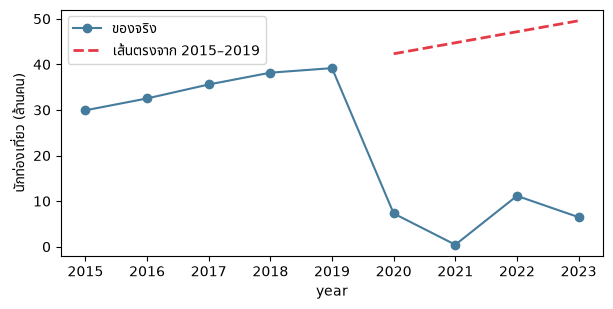

In [7]:
tour = pd.read_csv(
    DATA / "tourist_arrivals" / "tourist_arrivals_by_country.csv")
yearly = tour.groupby("year")["tourist_number"].sum() / 1e6
history = yearly.loc[2015:2019]        # ก่อนโควิด — ขึ้นสวยมาก

m, b = np.polyfit(history.index, history, 1)
future = np.array([2020, 2021, 2022, 2023])
forecast = np.polyval([m, b], future)

fig, ax = plt.subplots(figsize=(7, 3.2))
yearly.plot.line(ax=ax, color="#457b9d", marker="o",
                 label="ของจริง")
ax.plot(future, forecast, "--", color="#e63946", lw=2,
        label="เส้นตรงจาก 2015–2019")
ax.legend()
ax.set_ylabel("นักท่องเที่ยว (ล้านคน)")
plt.show()

เส้นประสัญญาว่าปี 2020 ควรมีนักท่องเที่ยว ~41 ล้าน —
**ของจริงคือ 7 ล้าน** (โควิด-19 ปิดโลกทั้งปี)

บทเรียนที่ยังอยู่กับผู้เรียนไปทั้งชีวิตทำงาน:

- เส้นตรงเป็นแค่**สมมติฐาน**ว่า "อดีตจะต่อเนื่องไปถึงอนาคต" — ไม่ใช่คำสั่ง
  ของอนาคต
- ยิ่งยืดไกลจากข้อมูล ยิ่งเชื่อไม่ได้ (พยากรณ์ 1-2 ช่วงต่อไป ≠ พยากรณ์ 5 ปี)
- เมื่อเล่าให้ผู้บริหารฟัง ต้องบอก**เงื่อนไข**ด้วย: "ถ้าทุกอย่างเดินตามดังเดิม"

**ตัวเลขปี 2023 ของไฟล์นี้ยังไม่สมบูรณ์** (ระบบรายงานยังตามไม่ทัน
ตัวเลขทางการ ~28 ล้าน) — อีกบทเรียน: ตรวจความครบถ้วนก่อนใช้ข้อมูลท้ายชุด

## 3. วงรอบ — เมื่อข้อมูลมีจังหวะประจำ

AirPassengers: จำนวนผู้โดยสารการบินรายเดือน (พ.ศ. ไม่ใช่ — ค.ศ.
1949–1960, หน่วยพันคน) ชุดคลาสสิกที่สอนเรื่องนี้มากว่า 50 ปี:

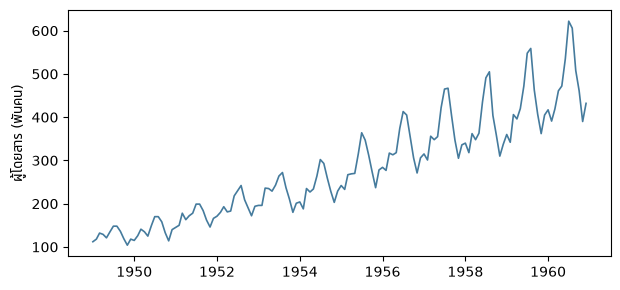

In [8]:
air = pd.read_csv(DATA / "air_passengers" / "AirPassengers.csv")
air["month"] = pd.date_range("1949-01", periods=len(air), freq="MS")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(air["month"], air["value"], color="#457b9d", lw=1.2)
ax.set_ylabel("ผู้โดยสาร (พันคน)")
plt.show()

สองชั้นชัดเจนยิ่งกว่า CO2: ขึ้นทุกปี **และ** หยักประจำ —
สูงกลางปี (ฤดูร้อนตะวันตก) ต่ำหัวปี ซ้ำแบบนาฬิกาทุกปี

**การพยากรณ์ง่ายที่สุดของโลกสำหรับข้อมูลมีวงรอบ:**
"ปีหน้าเดือนนี้ ≈ ปีนี้เดือนนี้" — เลื่อนข้อมูลไป 12 เดือนด้วย `.shift(12)`
แล้วตรวจว่ามันพลาดแค่ไหน:

ทำนายเดือนนี้ = ปีก่อนเดือนเดียวกัน: พลาดเฉลี่ย 32 พันคน


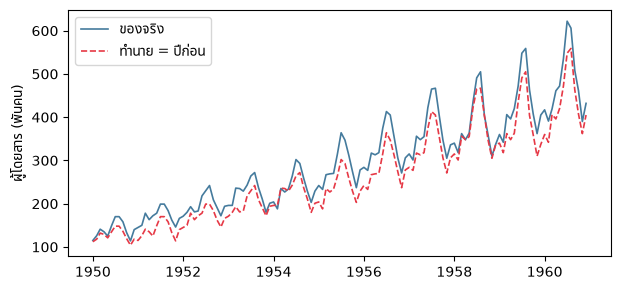

In [9]:
air["naive"] = air["value"].shift(12)   # ปีก่อนเดือนเดียวกัน

test = air.iloc[12:]                    # ตัด 12 เดือนแรก (ไม่มีค่าเทียบ)
mae = (test["value"] - test["naive"]).abs().mean()
print(f"ทำนายเดือนนี้ = ปีก่อนเดือนเดียวกัน: พลาดเฉลี่ย {mae:,.0f} พันคน")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(test["month"], test["value"], color="#457b9d", lw=1.2,
        label="ของจริง")
ax.plot(test["month"], test["naive"], color="#e63946", lw=1.2,
        linestyle="--", label="ทำนาย = ปีก่อน")
ax.legend()
ax.set_ylabel("ผู้โดยสาร (พันคน)")
plt.show()

เส้นประกาวตามเส้นจริงแน่นมาก — วงรอบแข็งแรงพอจะเป็นฐานการพยากรณ์
ระดับ "ใช้ได้จริง" ได้เลย โดยไม่ต้องพึ่งอะไรซับซ้อน

### โบนัสไทย 1 — PM2.5: moving average ทำให้กราฟอ่านออก

ข้อมูลรายวัน PM2.5 ปี 2568 สถานี 02T (ธนบุรี) — ดิบกระตุกทุกวัน:

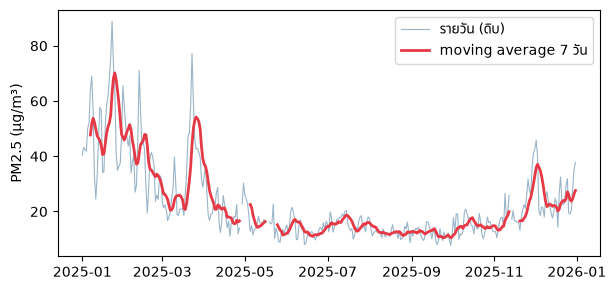

In [10]:
pm25 = pd.read_csv(DATA / "pcd_pm25_2025"
                   / "pm25_daily_2025_15stations.csv")
bkk = pm25[pm25["station_code"] == "02T"].copy()
bkk["date"] = pd.to_datetime(bkk["observation_date"])
bkk["ma7"] = bkk["measured_value"].rolling(7).mean()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(bkk["date"], bkk["measured_value"], color="#9ab5c9",
        lw=0.8, label="รายวัน (ดิบ)")
ax.plot(bkk["date"], bkk["ma7"], color="#e63946", lw=2,
        label="moving average 7 วัน")
ax.legend()
ax.set_ylabel("PM2.5 (µg/m³)")
plt.show()

เส้นหนาแสดง "ค่าเฉลี่ยสัปดาห์ที่แล้ว" — วาดกราฟรายงานแบบนี้
ผู้อ่านเห็นทิศทางทันที ไม่ตกใจกับวันเดียวที่เลขพุ่ง

### โบนัสไทย 2 — ราคาข้าวหอมมะลิ: trend line รายเดือน

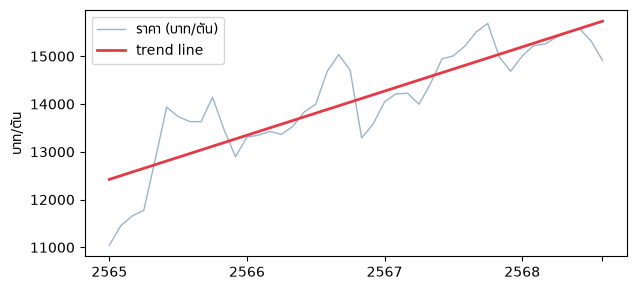

In [11]:
rice = pd.read_csv(DATA / "rice_price_105" / "rice105_monthly.csv")
# 44 เดือน (2565 เม.ย.–2568 ส.ค.) — สร้างลำดับ x เป็นตัวเลข 1..44
rice["seq"] = range(1, len(rice) + 1)
slope, intercept = np.polyfit(rice["seq"], rice["Value"], 1)
rice["trend"] = np.polyval([slope, intercept], rice["seq"])

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(rice["seq"], rice["Value"], color="#9ab5c9", lw=1,
        label="ราคา (บาท/ตัน)")
ax.plot(rice["seq"], rice["trend"], color="#e63946", lw=2,
        label="trend line")
ax.set_xticks([1, 13, 25, 37, 44])
ax.set_xticklabels(["2565", "2566", "2567", "2568", ""])
ax.legend()
ax.set_ylabel("บาท/ตัน")
plt.show()

## ✏️ ลองเอง 2 — วัด MAE ของ naive forecast

คำนวณ MAE ระหว่าง `air["value"]` กับ `air["naive"]` (ตัดแถวที่ยังไม่มีค่าเทียบออกก่อน) แล้วพิมพ์ออกมาหนึ่งตัวเลข ทศนิยม 1 ตำแหน่ง (หน่วยพันคน)

**คำใบ้:** เลือกสองคอลัมน์ด้วย `air[["value", "naive"]]` แล้ว `.dropna()` ก่อนหาผลต่าง `.abs().mean()`

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# พิมพ์ MAE หนึ่งตัวเลข (ทศนิยม 1 ตำแหน่ง) — ควรได้ราว 32


<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

<pre style="margin:8px 0 0 0; white-space:pre-wrap; color:#123d6b;">32.0</pre>

</div>

## 4. เช็คลิสต์ "ควรเชื่อการพยากรณ์นี้ไหม" — 5 ข้อ

1. **ตรวจแล้วหรือยัง** — ซ่อนท้าย ทำนาย เทียบจริง (MAE เล็กไหม?)
2. **ช่วงพยากรณ์สั้นกว่าช่วงข้อมูล** — ข้อมูล 5 ปี พยากรณ์เดือนหน้า/ปีหน้า
   โอเค; พยากรณ์ 10 ปี ไม่โอเค
3. **โลกเปลี่ยนไหม** — กฎ/เทคโนโลยี/พฤติกรรมเปลี่ยน = เส้นเก่าใช้ไม่ได้
4. **มีวงรอบ** — จับวงรอบมาช่วย (เทียบปีก่อนเดือนเดียวกัน)
5. **พูดเงื่อนไข** — "ถ้าทุกอย่างเดินตามดังเดิม" ต้องติดปากเสมอ

**ต่อไป (M7):** ทั้งหมดที่ทำมือมาสองวัน — จะยกให้คอมพิวเตอร์ทำแทน